# วิเคราะห์ข้อมูล (Regression)
เป้าหมายคือ `int.rate` (ดอกเบี้ยที่ได้) ไม่ใช้ `not.fully.paid` เป็น feature เพราะรู้หลังจากตั้งดอกเบี้ยแล้ว (data leakage)

ผลลัพธ์: `Results/Regression/00_Data_Analysis/`

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

import numpy as np
from project import Outputs, regression_data
import pandas as pd
import plots

out = Outputs("Regression", "00_Data_Analysis")
d = regression_data()
print(f"train {d.X_train.shape} | test {d.X_test.shape} | target int.rate | {len(d.feature_cols)} features")

train (7662, 20) | test (1916, 20) | target int.rate | 20 features


In [2]:
df, X, y, cols = d.df, d.X, d.y, d.feature_cols
print(f"rows x columns: {df.shape} | missing values: {int(df.isnull().sum().sum())}")
print(f"int.rate: mean {y.mean():.4f}, std {y.std():.4f}, min {y.min():.4f}, max {y.max():.4f}")
pd.DataFrame(
    {
        "statistic": [
            "rows",
            "columns",
            "missing_values",
            "int.rate_mean",
            "int.rate_std",
            "int.rate_min",
            "int.rate_max",
        ],
        "value": [
            len(df),
            df.shape[1],
            int(df.isnull().sum().sum()),
            df["int.rate"].mean(),
            df["int.rate"].std(),
            df["int.rate"].min(),
            df["int.rate"].max(),
        ],
    }
).to_csv(out.table("summary_stats.csv"), index=False)
corr = pd.Series({c: np.corrcoef(X[:, i], y)[0, 1] for i, c in enumerate(cols)})
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
corr.rename("correlation_with_int.rate").to_csv(out.table("correlation_with_int_rate.csv"), index_label="feature")
print("\ntop correlations with int.rate:")
print(corr.head(8).to_string())

rows x columns: (9578, 14) | missing values: 0
int.rate: mean 0.1226, std 0.0268, min 0.0600, max 0.2164

top correlations with int.rate:
fico               -0.714821
revol.util          0.464837
high_revol_util     0.325105
credit.policy      -0.294089
installment         0.276140
dti                 0.220006
inq.last.6mths      0.202780
bad_history_flag    0.189619


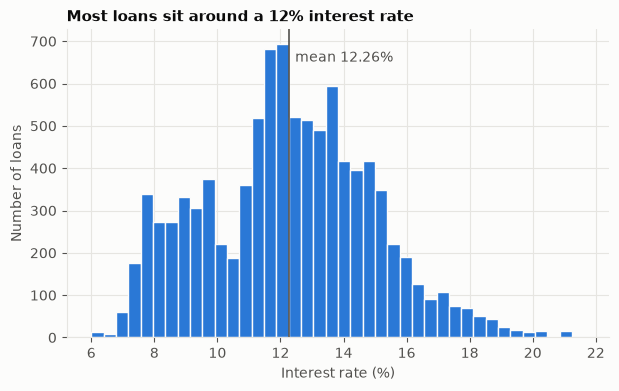

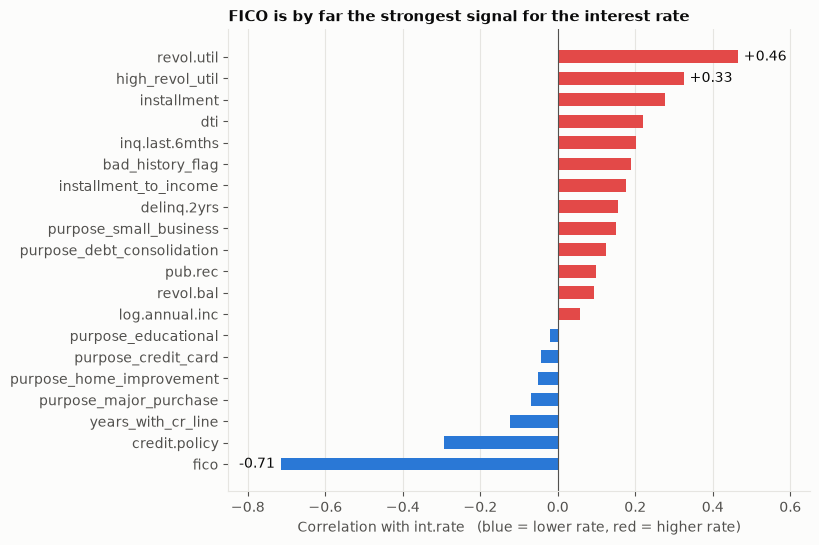

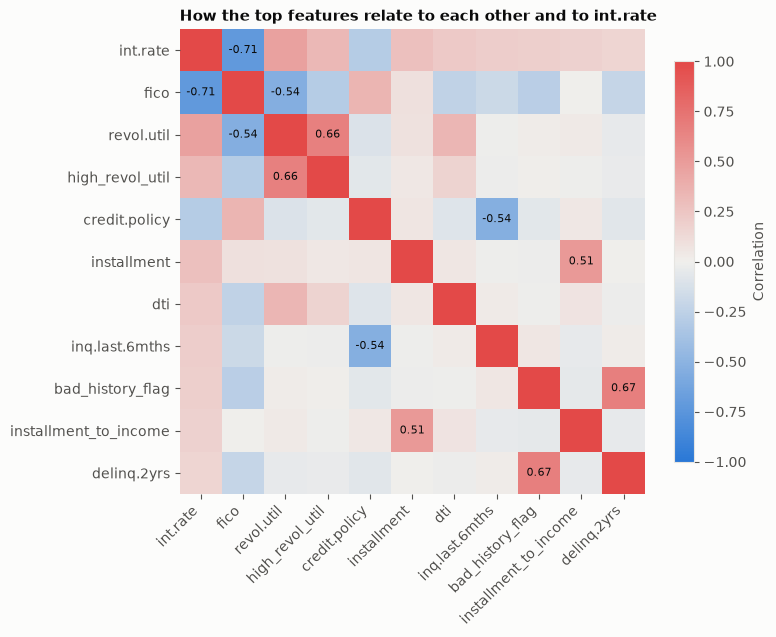

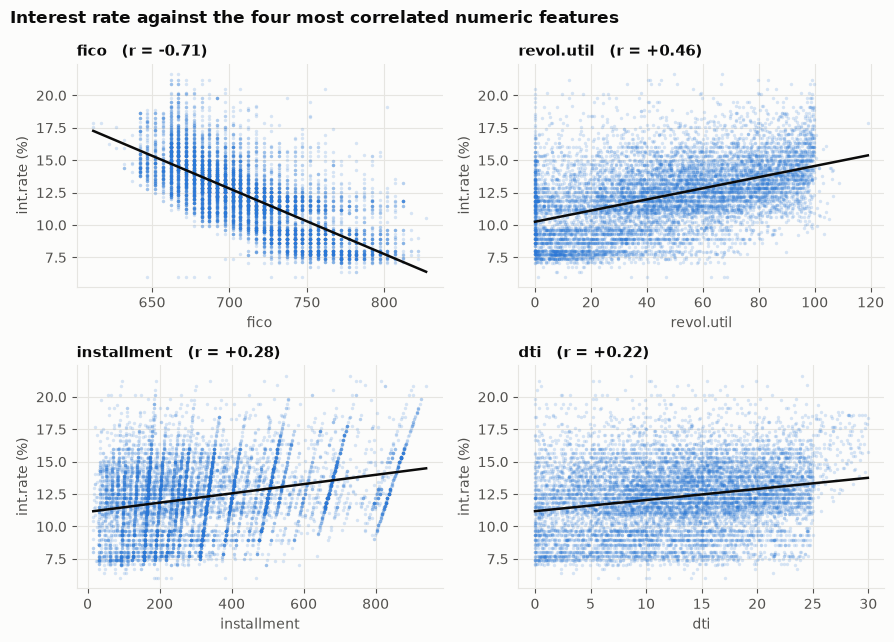

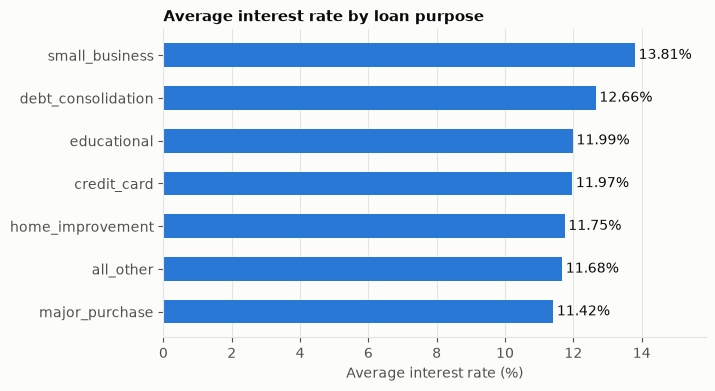

In [3]:
numeric = [c for i, c in enumerate(cols) if len(np.unique(X[:, i])) > 2]
top4 = list(corr[numeric].abs().sort_values(ascending=False).index[:4])
plots.plot_target_distribution(y, out.image("int_rate_distribution.png"))
plots.plot_correlation_bars(corr, out.image("correlation_with_int_rate.png"))
plots.plot_correlation_heatmap(X, cols, y, corr, out.image("correlation_heatmap.png"))
plots.plot_top_features_scatter(X, cols, y, top4, out.image("top_features_vs_int_rate.png"))
plots.plot_rate_by_purpose(df, out.image("int_rate_by_purpose.png"))